# Exercise 3 · Titanic survival classifier

**Book:** Chapter 3, Exercise 3

**Task:** predict passenger survival from class, sex, age, family, fare and port.

`test.csv` has no labels (Kaggle's submission set), so 10-fold CV on `train.csv` is the performance estimate.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

from homl.datasets import load_titanic
from homl.plotting import RANDOM_STATE, save_fig

train, test = load_titanic()
print(train.shape, test.shape)
train.head()

(891, 12) (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Exploration
Missing: `Age` (~20%), `Cabin` (~77%), two `Embarked` values.

In [2]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


overall survival rate: 0.384


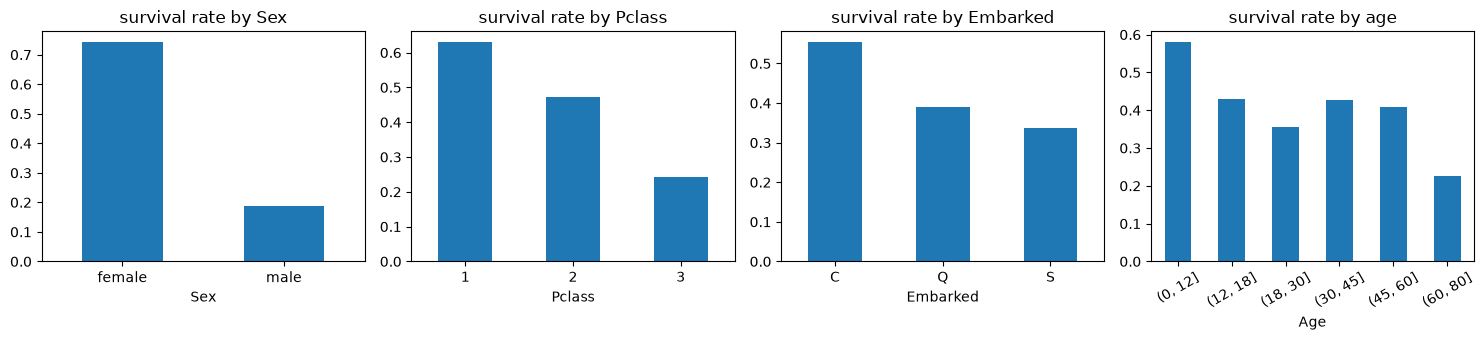

In [3]:
print(f"overall survival rate: {train['Survived'].mean():.3f}")
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, col in zip(axes[:3], ["Sex", "Pclass", "Embarked"]):
    train.groupby(col)["Survived"].mean().plot.bar(ax=ax, rot=0, title=f"survival rate by {col}")
train.groupby(pd.cut(train["Age"], [0, 12, 18, 30, 45, 60, 80]), observed=True)["Survived"].mean().plot.bar(
    ax=axes[3], rot=30, title="survival rate by age")
save_fig("survival_rates")
plt.show()

Sex is the strongest signal, then class; age matters mostly for young children.

## Feature engineering
**Title** from `Name` (identifies boys via "Master" even without `Age`), **FamilySize**, **IsAlone**, **CabinKnown**.

In [4]:
class TitanicFeatures(BaseEstimator, TransformerMixin):
    """Add Title, FamilySize, IsAlone and CabinKnown columns."""

    common_titles = {"Mr", "Mrs", "Miss", "Master"}
    aliases = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"}

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        title = X["Name"].str.extract(r",\s*([^\.]+)\.")[0].replace(self.aliases)
        X["Title"] = title.where(title.isin(self.common_titles), "Rare")
        X["FamilySize"] = X["SibSp"] + X["Parch"] + 1
        X["IsAlone"] = (X["FamilySize"] == 1).astype(int)
        X["CabinKnown"] = X["Cabin"].notna().astype(int)
        return X


feats = TitanicFeatures().transform(train)
feats.groupby("Title")["Survived"].agg(["mean", "count"]).round(3)

,mean,count
Title,,
Master,0.575,40
Miss,0.703,185
Mr,0.157,517
Mrs,0.794,126
Rare,0.348,23


## Preprocessing pipeline
Numbers: median imputation + scaling. Categories: most-frequent imputation + one-hot.

In [5]:
num_cols = ["Age", "SibSp", "Parch", "Fare", "FamilySize"]
cat_cols = ["Pclass", "Sex", "Embarked", "Title"]
pass_cols = ["IsAlone", "CabinKnown"]

preprocessing = ColumnTransformer(
    [
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
        ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), cat_cols),
        ("pass", "passthrough", pass_cols),
    ]
)

def make_model(estimator):
    return make_pipeline(TitanicFeatures(), preprocessing, estimator)

X_train = train.drop(columns="Survived")
y_train = train["Survived"]
preprocessing.fit(TitanicFeatures().transform(X_train)).get_feature_names_out()

array(['num__Age', 'num__SibSp', 'num__Parch', 'num__Fare',
       'num__FamilySize', 'cat__Pclass_1', 'cat__Pclass_2',
       'cat__Pclass_3', 'cat__Sex_female', 'cat__Sex_male',
       'cat__Embarked_C', 'cat__Embarked_Q', 'cat__Embarked_S',
       'cat__Title_Master', 'cat__Title_Miss', 'cat__Title_Mr',
       'cat__Title_Mrs', 'cat__Title_Rare', 'pass__IsAlone',
       'pass__CabinKnown'], dtype=object)

## Comparing models
10-fold stratified CV; on 891 rows the fold spread matters as much as the mean.

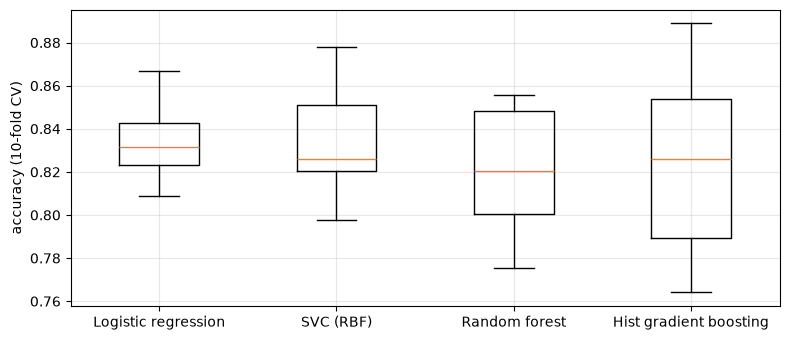

,mean,std
Logistic regression,0.8339,0.0175
SVC (RBF),0.8327,0.0230
Random forest,0.8215,0.0265
Hist gradient boosting,0.8237,0.0382


In [6]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
candidates = {
    "Logistic regression": LogisticRegression(max_iter=1_000),
    "SVC (RBF)": SVC(random_state=RANDOM_STATE),
    "Random forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Hist gradient boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}
cv_scores = {name: cross_val_score(make_model(est), X_train, y_train, cv=cv, n_jobs=-1)
             for name, est in candidates.items()}

plt.figure(figsize=(8, 3.5))
plt.boxplot(list(cv_scores.values()), tick_labels=list(cv_scores.keys()))
plt.ylabel("accuracy (10-fold CV)"); plt.grid(alpha=0.3)
save_fig("model_comparison")
plt.show()
pd.DataFrame({k: [v.mean(), v.std()] for k, v in cv_scores.items()}, index=["mean", "std"]).T.round(4)

## Tuning
The SVC and random forest have the hyperparameters most worth tuning.

In [7]:
svc_search = GridSearchCV(
    make_model(SVC(random_state=RANDOM_STATE)),
    {"svc__C": [0.3, 1, 3, 10], "svc__gamma": ["scale", 0.03, 0.1]},
    cv=cv, n_jobs=-1,
).fit(X_train, y_train)
rf_search = GridSearchCV(
    make_model(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1)),
    {"randomforestclassifier__max_depth": [4, 6, 8, None],
     "randomforestclassifier__min_samples_leaf": [1, 3, 5]},
    cv=cv, n_jobs=-1,
).fit(X_train, y_train)
print(f"SVC best:    {svc_search.best_score_:.4f} {svc_search.best_params_}")
print(f"Forest best: {rf_search.best_score_:.4f} {rf_search.best_params_}")
best = max([svc_search, rf_search], key=lambda s: s.best_score_)

SVC best:    0.8372 {'svc__C': 3, 'svc__gamma': 0.03}
Forest best: 0.8350 {'randomforestclassifier__max_depth': 8, 'randomforestclassifier__min_samples_leaf': 5}


## Predictions for the unlabeled test set
Written in Kaggle's format to `submissions/` (git-ignored).

In [8]:
out = Path("submissions"); out.mkdir(exist_ok=True)
submission = pd.DataFrame({"PassengerId": test["PassengerId"], "Survived": best.predict(test)})
submission.to_csv(out / "titanic_submission.csv", index=False)
print(submission["Survived"].value_counts(normalize=True).round(3))

Survived
0    0.612
1    0.388
Name: proportion, dtype: float64


## Results

In [9]:
summary = {name: s.mean() for name, s in cv_scores.items()}
summary["Tuned SVC"] = svc_search.best_score_
summary["Tuned random forest"] = rf_search.best_score_
pd.Series(summary, name="10-fold CV accuracy").sort_values(ascending=False).round(4).to_frame()

,10-fold CV accuracy
Tuned SVC,0.8372
Tuned random forest,0.8350
Logistic regression,0.8339
SVC (RBF),0.8327
Hist gradient boosting,0.8237
Random forest,0.8215


**Takeaways**
- Sex, class and the engineered `Title` carry most of the signal.
- All models land at 82–84% CV accuracy, within the fold-to-fold spread; the tuned SVC (83.7%) is only marginally best.